<a href="https://colab.research.google.com/github/ripon-cse24/99_days_of_coding_MLOps_With_CPC/blob/main/phase-1/day-012/day-012.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
data = pd.read_csv("/content/diabetes_dataset.csv")

In [26]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [27]:
data.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [28]:
data.shape

(768, 9)

In [29]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [30]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [31]:
data.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [32]:
data['BloodPressure'].unique()

array([ 72,  66,  64,  40,  74,  50,   0,  70,  96,  92,  80,  60,  84,
        30,  88,  90,  94,  76,  82,  75,  58,  78,  68, 110,  56,  62,
        85,  86,  48,  44,  65, 108,  55, 122,  54,  52,  98, 104,  95,
        46, 102, 100,  61,  24,  38, 106, 114])

In [33]:
data['BloodPressure'].value_counts()

,count
BloodPressure,
70,57
74,52
78,45
68,45
72,44
64,43
80,40
76,39
60,37


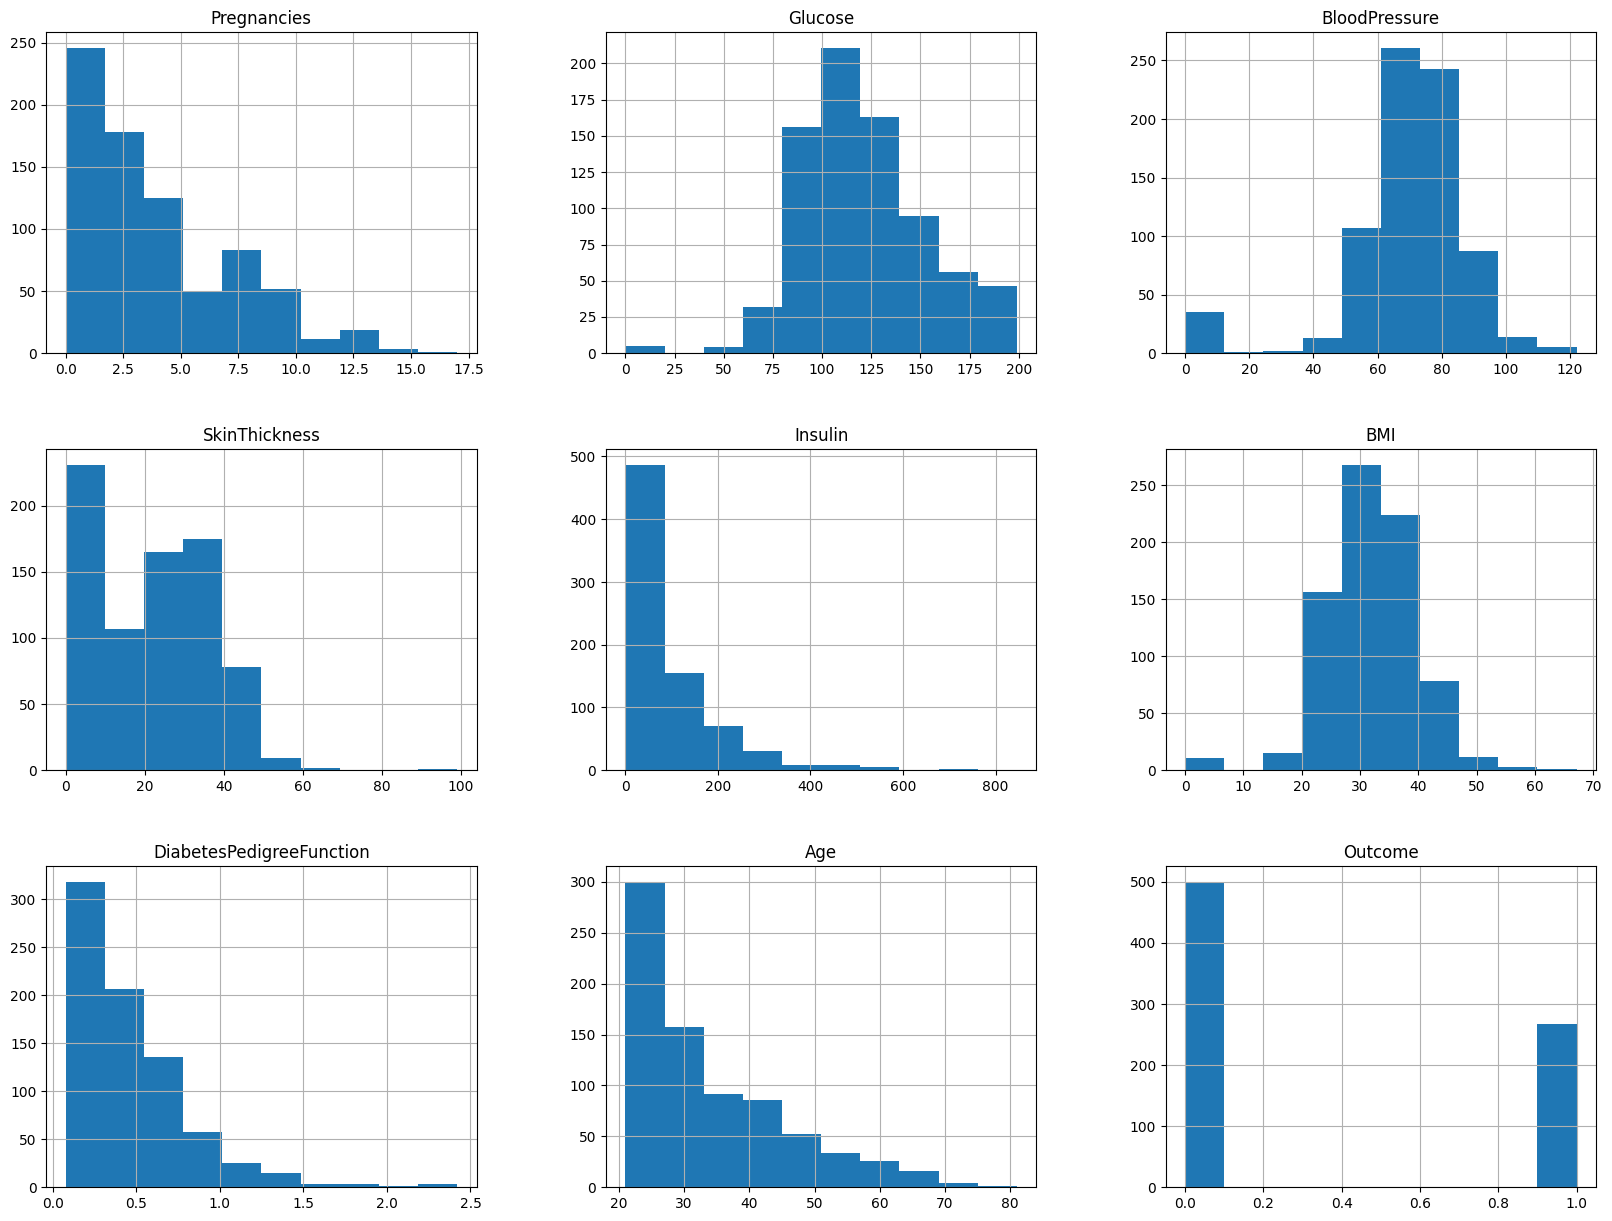

In [34]:
data.hist(figsize=(20,15))
plt.show()

In [35]:
data.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [36]:
data[['Glucose', 'BMI', 'BloodPressure', 'Insulin', 'SkinThickness']].corr()

,Glucose,BMI,BloodPressure,Insulin,SkinThickness
Glucose,1.000000,0.221071,0.152590,0.331357,0.057328
BMI,0.221071,1.000000,0.281805,0.197859,0.392573
BloodPressure,0.152590,0.281805,1.000000,0.088933,0.207371
Insulin,0.331357,0.197859,0.088933,1.000000,0.436783
SkinThickness,0.057328,0.392573,0.207371,0.436783,1.000000


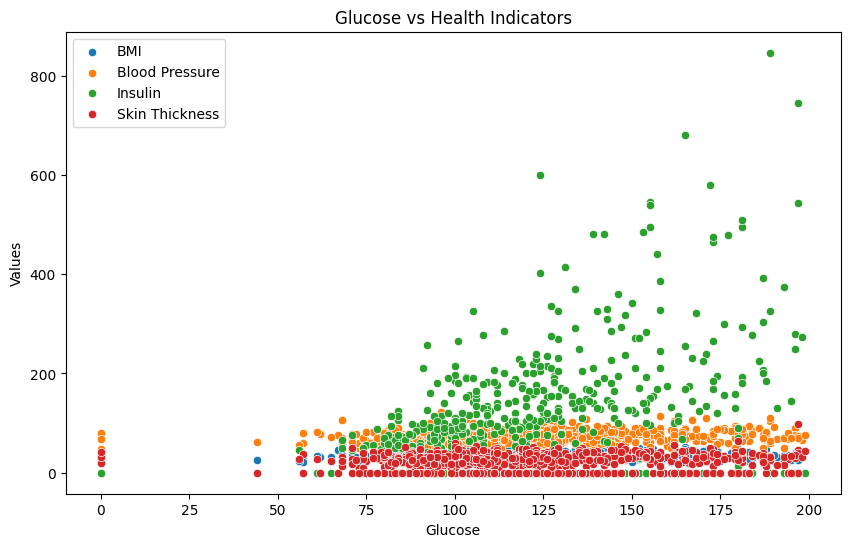

In [37]:
plt.figure(figsize = (10, 6))

sns.scatterplot(data = data, x = 'Glucose', y = 'BMI', label = 'BMI')
sns.scatterplot(data = data, x = 'Glucose', y = 'BloodPressure', label = 'Blood Pressure')
sns.scatterplot(data = data, x = 'Glucose', y = 'Insulin', label = 'Insulin')
sns.scatterplot(data = data, x = 'Glucose', y = 'SkinThickness', label = 'Skin Thickness')

plt.title('Glucose vs Health Indicators')
plt.xlabel('Glucose')
plt.ylabel('Values')
plt.legend(loc = 'upper left')
plt.show()

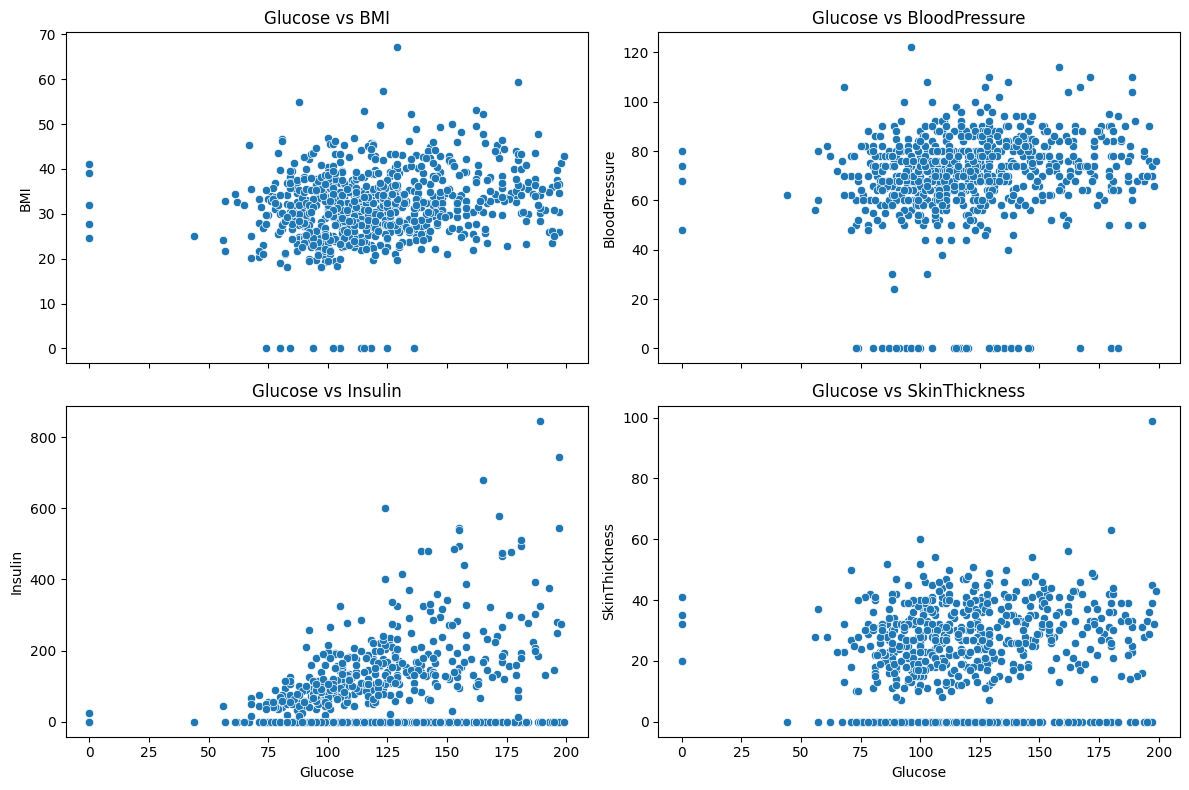

In [38]:
fig, axes = plt.subplots(2, 2, figsize = (12, 8), sharex = True)

sns.scatterplot(data=data, x='Glucose', y='BMI', ax=axes[0, 0])
sns.scatterplot(data=data, x='Glucose', y='BloodPressure', ax=axes[0, 1])
sns.scatterplot(data=data, x='Glucose', y='Insulin', ax=axes[1, 0])
sns.scatterplot(data=data, x='Glucose', y='SkinThickness', ax=axes[1, 1])

axes[0, 0].set_title('Glucose vs BMI')
axes[0, 1].set_title('Glucose vs BloodPressure')
axes[1, 0].set_title('Glucose vs Insulin')
axes[1, 1].set_title('Glucose vs SkinThickness')

plt.tight_layout()
plt.show()